In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from io import StringIO

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

print("All libraries imported successfully!")


All libraries imported successfully!


In [7]:

url = "https://api.frankfurter.dev/v2/rates.csv"

params = {
    "base": "GBP",
    "quotes": "EUR,USD,INR",
    "from": "2019-01-01"
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

df = pd.read_csv(StringIO(response.text))

print("Data downloaded successfully!")
print(df.head())
print("Dataset shape:", df.shape)


Data downloaded successfully!
         date base quote    rate
0  2019-01-01  GBP   EUR  1.1119
1  2019-01-01  GBP   INR 88.8400
2  2019-01-01  GBP   USD  1.2723
3  2019-01-02  GBP   EUR  1.1110
4  2019-01-02  GBP   INR 88.7600
Dataset shape: (8625, 4)


In [8]:

# Convert date column
df["date"] = pd.to_datetime(df["date"])

# Sort records
df = df.sort_values(["date", "quote"])

# Convert long format into wide format
df_wide = df.pivot(
    index="date",
    columns="quote",
    values="rate"
).reset_index()

df_wide.columns.name = None

# Sort by date
df_wide = df_wide.sort_values("date").reset_index(drop=True)

# Check duplicates and missing values
print("Duplicate rows:", df_wide.duplicated().sum())
print("\nMissing values:")
print(df_wide.isnull().sum())

print("\nCleaned dataset:")
print(df_wide.head())


Duplicate rows: 0

Missing values:
date    0
EUR     0
INR     0
USD     0
dtype: int64

Cleaned dataset:
        date    EUR     INR    USD
0 2019-01-01 1.1119 88.8400 1.2723
1 2019-01-02 1.1110 88.7600 1.2700
2 2019-01-03 1.1074 88.4700 1.2601
3 2019-01-04 1.1093 88.3600 1.2637
4 2019-01-05 1.1096 88.3300 1.2643


In [9]:

print("Number of records:", df_wide.shape[0])
print("Number of columns:", df_wide.shape[1])

print("\nDataset information:")
df_wide.info()

print("\nStatistical summary:")
print(df_wide.describe())

print("\nDate range:")
print(df_wide["date"].min())
print(df_wide["date"].max())


Number of records: 2875
Number of columns: 4

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2875 entries, 0 to 2874
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    2875 non-null   datetime64[ns]
 1   EUR     2875 non-null   float64       
 2   INR     2875 non-null   float64       
 3   USD     2875 non-null   float64       
dtypes: datetime64[ns](1), float64(3)
memory usage: 90.0 KB

Statistical summary:
                      date       EUR       INR       USD
count                 2875 2875.0000 2875.0000 2875.0000
mean   2022-12-08 00:00:00    1.1579  103.9851    1.2940
min    2019-01-01 00:00:00    1.0728   83.7800    1.0720
25%    2020-12-19 12:00:00    1.1430   95.5550    1.2535
50%    2022-12-08 00:00:00    1.1614  102.0600    1.2960
75%    2024-11-25 12:00:00    1.1749  109.0050    1.3412
max    2026-11-14 00:00:00    1.2135  130.4600    1.4189
std                    Na

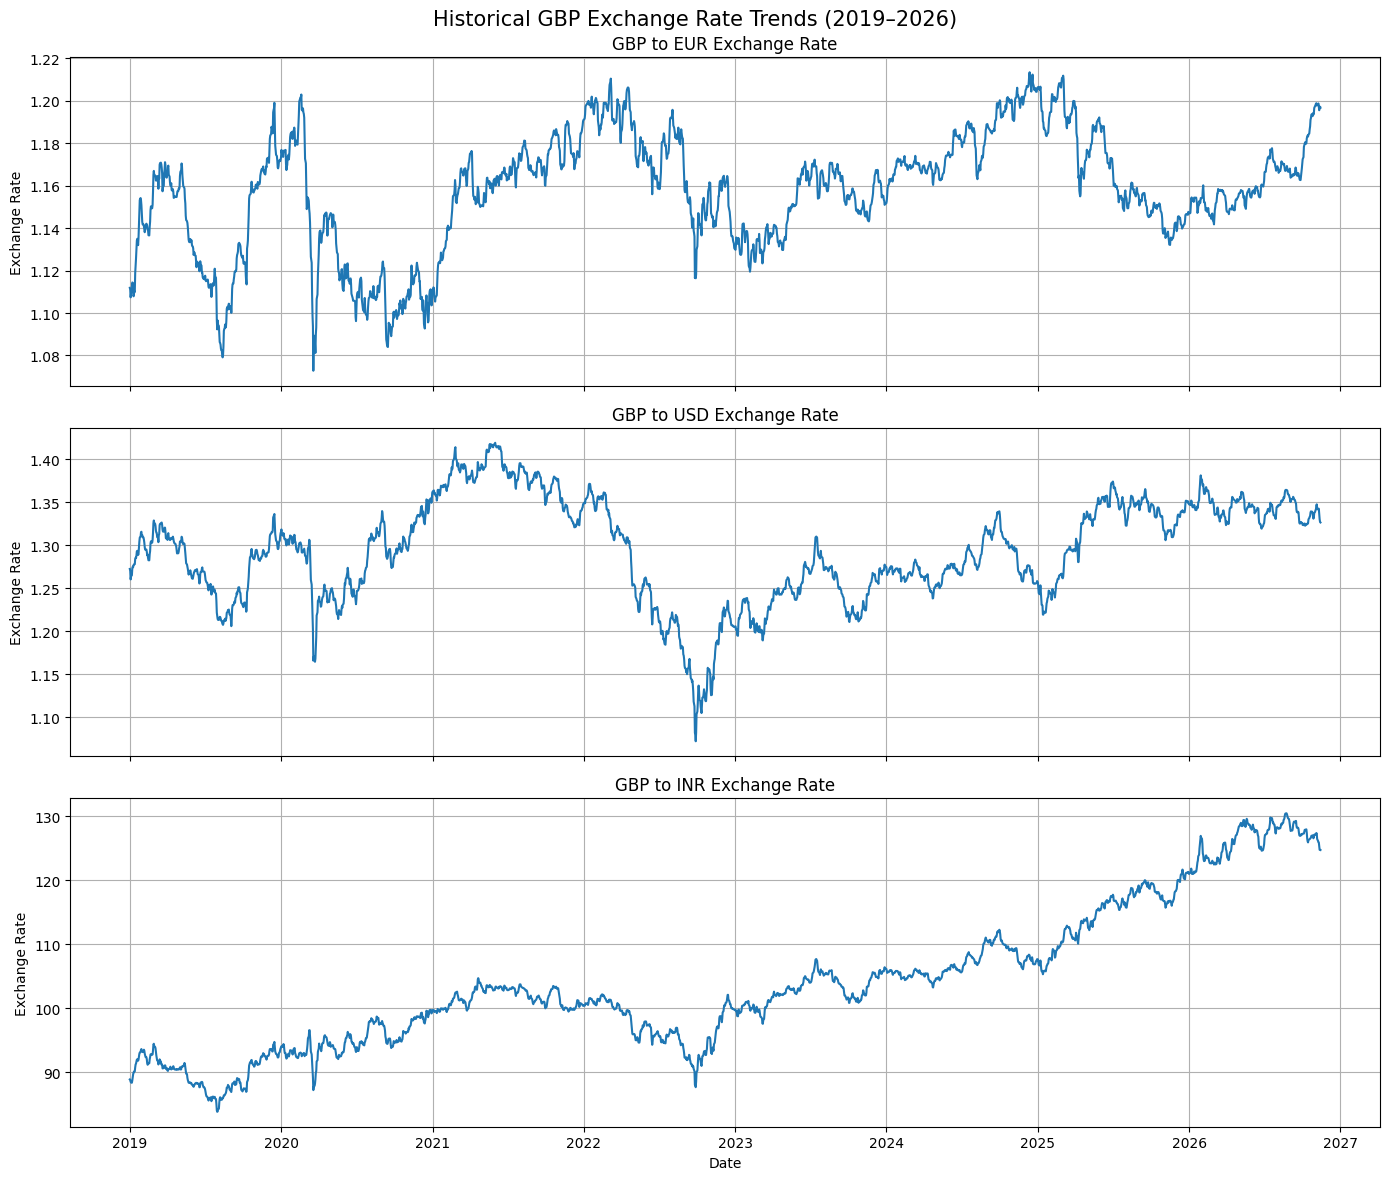

In [12]:

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

currencies = ["EUR", "USD", "INR"]

for ax, currency in zip(axes, currencies):
    ax.plot(df_wide["date"], df_wide[currency])
    ax.set_title(f"GBP to {currency} Exchange Rate")
    ax.set_ylabel("Exchange Rate")
    ax.grid(True)

axes[-1].set_xlabel("Date")

plt.suptitle("Historical GBP Exchange Rate Trends (2019–2026)", fontsize=15)
plt.tight_layout()
plt.show()


In [13]:

# Calculate average exchange rates

average_rates = df_wide[["EUR", "USD", "INR"]].mean()

print("Average Exchange Rates (2019–2026):")
print(average_rates.round(4))


Average Exchange Rates (2019–2026):
EUR     1.1579
USD     1.2940
INR   103.9851
dtype: float64


In [14]:

# Calculate daily percentage changes
daily_returns = df_wide[["EUR", "USD", "INR"]].pct_change() * 100

# Calculate annualised volatility
annual_volatility = daily_returns.std() * np.sqrt(252)

print("Annualised Exchange Rate Volatility (%):")
print(annual_volatility.round(2).sort_values(ascending=False))


Annualised Exchange Rate Volatility (%):
USD   4.7400
INR   4.6000
EUR   3.3500
dtype: float64


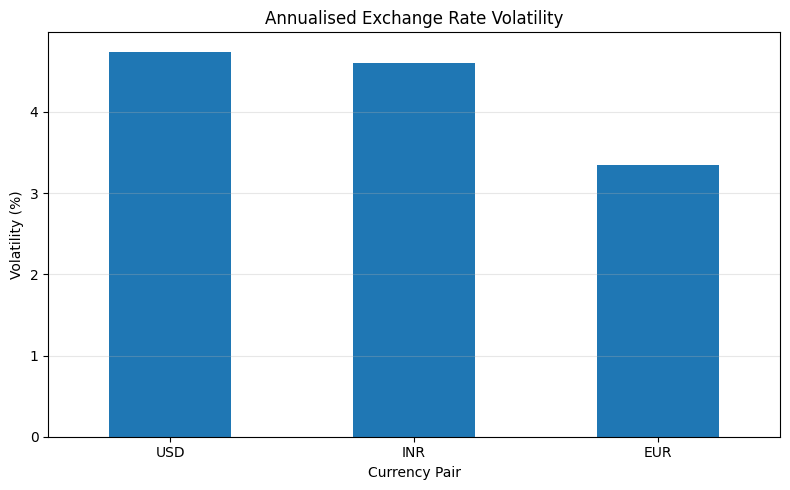

In [15]:

# Plot annualised volatility

plt.figure(figsize=(8, 5))

annual_volatility.sort_values(ascending=False).plot(
    kind="bar",
    title="Annualised Exchange Rate Volatility"
)

plt.xlabel("Currency Pair")
plt.ylabel("Volatility (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:

# Find the largest daily increases and decreases

results = []

for currency in ["EUR", "USD", "INR"]:

    # Largest daily increase
    max_idx = daily_returns[currency].idxmax()

    # Largest daily decrease
    min_idx = daily_returns[currency].idxmin()

    results.append({
        "Currency": currency,
        "Largest Increase (%)": daily_returns.loc[max_idx, currency],
        "Increase Date": df_wide.loc[max_idx, "date"],
        "Largest Decrease (%)": daily_returns.loc[min_idx, currency],
        "Decrease Date": df_wide.loc[min_idx, "date"]
    })

movement_summary = pd.DataFrame(results)

print("Largest Daily Exchange Rate Movements:")
display(movement_summary.round(4))


Largest Daily Exchange Rate Movements:


,Currency,Largest Increase (%),Increase Date,Largest Decrease (%),Decrease Date
0,EUR,1.5177,2019-10-11,-1.9109,2020-03-19
1,USD,2.0952,2020-03-27,-2.9958,2020-03-19
2,INR,1.6975,2020-03-27,-2.3302,2022-09-26


Correlation Between Currency Pair Daily Returns:


,EUR,USD,INR
EUR,1.0000,0.5850,0.5420
USD,0.5850,1.0000,0.8590
INR,0.5420,0.8590,1.0000


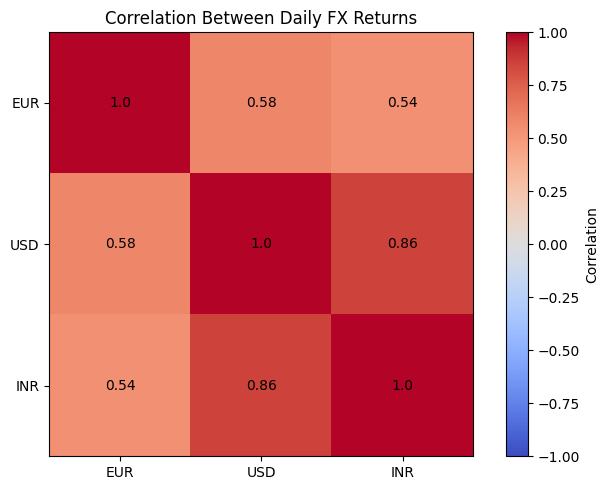

In [17]:

# Calculate correlation between daily currency movements

correlation_matrix = daily_returns[["EUR", "USD", "INR"]].corr()

print("Correlation Between Currency Pair Daily Returns:")
display(correlation_matrix.round(3))

# Visualise the correlation matrix

plt.figure(figsize=(7, 5))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(range(3), correlation_matrix.columns)
plt.yticks(range(3), correlation_matrix.columns)

for i in range(3):
    for j in range(3):
        plt.text(
            j, i,
            round(correlation_matrix.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.title("Correlation Between Daily FX Returns")
plt.tight_layout()
plt.show()


Monthly Average Exchange Rates:


,EUR,USD,INR
date,,,
2019-01-31,1.1274,1.2874,91.0123
2019-02-28,1.1447,1.2995,92.5507
2019-03-31,1.1651,1.3172,91.6474
2019-04-30,1.1593,1.3030,90.4863
2019-05-31,1.1495,1.2860,89.7574
2019-06-30,1.1233,1.2673,88.0470
2019-07-31,1.1129,1.2491,85.8952
2019-08-31,1.0928,1.2154,86.2823
2019-09-30,1.1212,1.2350,88.0637


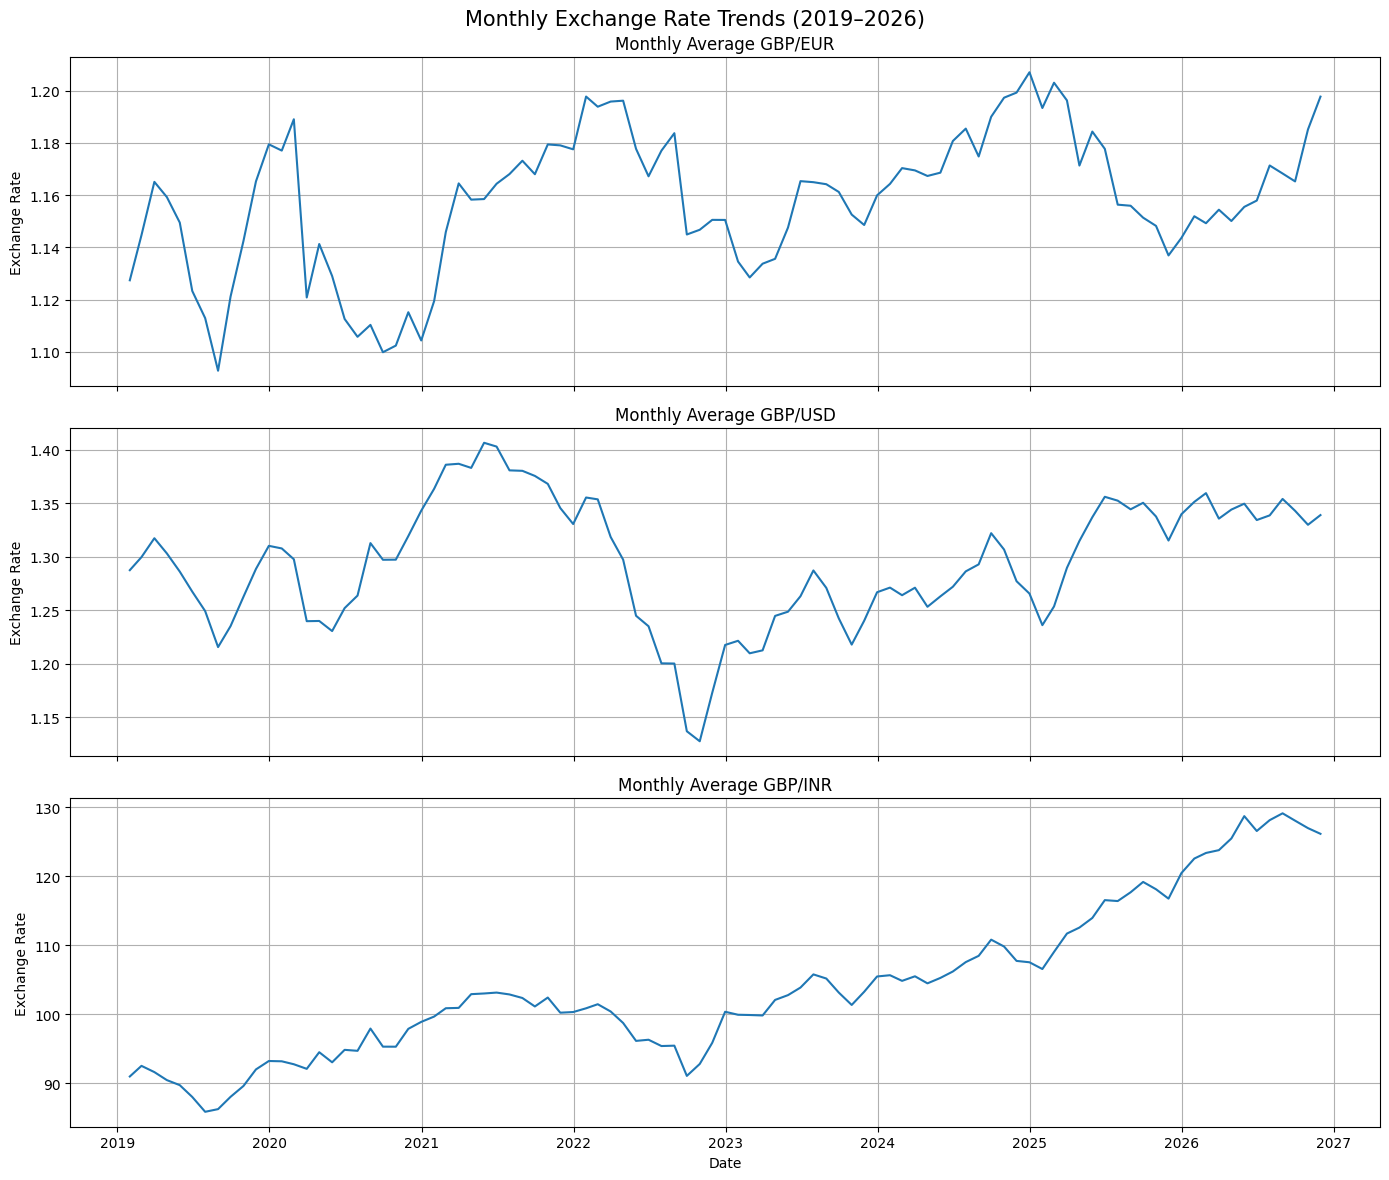

In [18]:

# Calculate monthly average exchange rates

monthly_rates = (
    df_wide.set_index("date")[["EUR", "USD", "INR"]]
    .resample("ME")
    .mean()
)

print("Monthly Average Exchange Rates:")
display(monthly_rates.head(12).round(4))

# Plot monthly trends separately

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

for ax, currency in zip(axes, ["EUR", "USD", "INR"]):
    ax.plot(monthly_rates.index, monthly_rates[currency])
    ax.set_title(f"Monthly Average GBP/{currency}")
    ax.set_ylabel("Exchange Rate")
    ax.grid(True)

axes[-1].set_xlabel("Date")

plt.suptitle("Monthly Exchange Rate Trends (2019–2026)", fontsize=15)
plt.tight_layout()
plt.show()


In [19]:

# Calculate annual average exchange rates

annual_rates = (
    df_wide.groupby(df_wide["date"].dt.year)[["EUR", "USD", "INR"]]
    .mean()
)

print("Annual Average Exchange Rates:")
display(annual_rates.round(4))

# Calculate year-on-year percentage changes
annual_changes = annual_rates.pct_change() * 100

print("\nYear-on-Year Percentage Changes:")
display(annual_changes.round(2))


Annual Average Exchange Rates:


,EUR,USD,INR
date,,,
2019,1.1402,1.2766,89.8697
2020,1.1254,1.2833,95.0698
2021,1.1631,1.3756,101.6863
2022,1.1734,1.2376,97.0793
2023,1.1499,1.2439,102.7587
2024,1.1812,1.2787,107.0230
2025,1.1680,1.3192,114.9696
2026,1.1627,1.3436,126.3158



Year-on-Year Percentage Changes:


,EUR,USD,INR
date,,,
2019,NaN,NaN,NaN
2020,-1.3000,0.5200,5.7900
2021,3.3500,7.2000,6.9600
2022,0.8900,-10.0400,-4.5300
2023,-2.0100,0.5100,5.8500
2024,2.7300,2.8000,4.1500
2025,-1.1200,3.1600,7.4300
2026,-0.4600,1.8500,9.8700


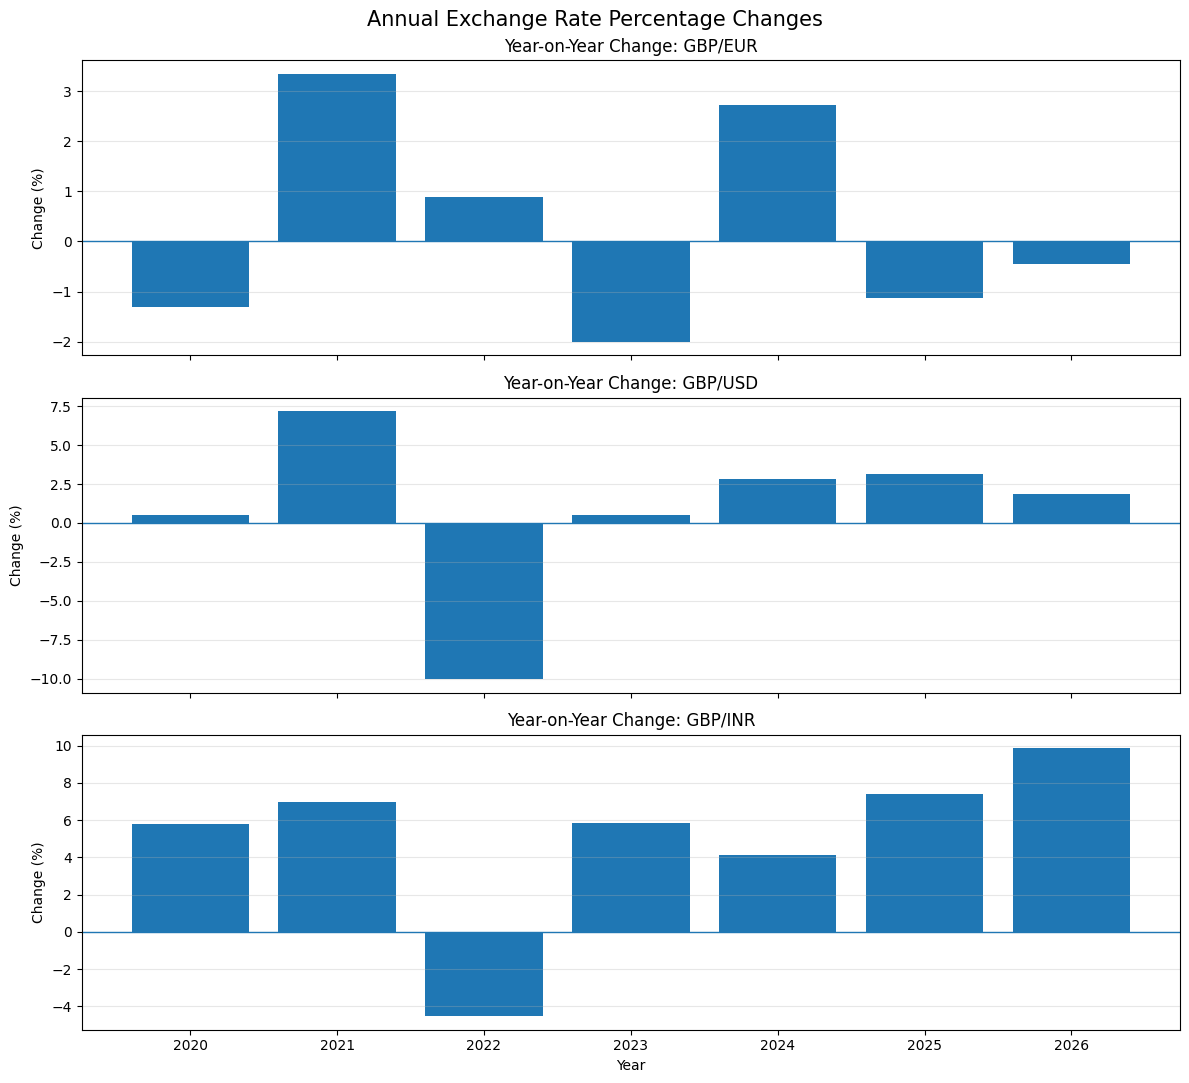

In [20]:

# Plot annual percentage changes

fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)

for ax, currency in zip(axes, ["EUR", "USD", "INR"]):

    ax.bar(
        annual_changes.index.astype(str),
        annual_changes[currency]
    )

    ax.axhline(y=0, linewidth=1)
    ax.set_title(f"Year-on-Year Change: GBP/{currency}")
    ax.set_ylabel("Change (%)")
    ax.grid(axis="y", alpha=0.3)

axes[-1].set_xlabel("Year")

plt.suptitle("Annual Exchange Rate Percentage Changes", fontsize=15)
plt.tight_layout()
plt.show()



In [21]:

# Create a forecasting dataset for GBP/USD

forecast_df = df_wide[["date", "USD"]].copy()

# Create previous-day exchange rate features
forecast_df["lag_1"] = forecast_df["USD"].shift(1)
forecast_df["lag_2"] = forecast_df["USD"].shift(2)
forecast_df["lag_3"] = forecast_df["USD"].shift(3)
forecast_df["lag_7"] = forecast_df["USD"].shift(7)

# Create the next-day target
forecast_df["target"] = forecast_df["USD"].shift(-1)

# Remove rows with missing values
forecast_df = forecast_df.dropna().reset_index(drop=True)

print("Forecasting dataset:")
display(forecast_df.head(10))

print("\nDataset shape:", forecast_df.shape)


Forecasting dataset:


,date,USD,lag_1,lag_2,lag_3,lag_7,target
0,2019-01-08,1.2749,1.2731,1.2649,1.2643,1.2723,1.2742
1,2019-01-09,1.2742,1.2749,1.2731,1.2649,1.2700,1.2768
2,2019-01-10,1.2768,1.2742,1.2749,1.2731,1.2601,1.2771
3,2019-01-11,1.2771,1.2768,1.2742,1.2749,1.2637,1.2778
4,2019-01-12,1.2778,1.2771,1.2768,1.2742,1.2643,1.2778
5,2019-01-13,1.2778,1.2778,1.2771,1.2768,1.2649,1.2839
6,2019-01-14,1.2839,1.2778,1.2778,1.2771,1.2731,1.2854
7,2019-01-15,1.2854,1.2839,1.2778,1.2778,1.2749,1.2849
8,2019-01-16,1.2849,1.2854,1.2839,1.2778,1.2742,1.2879
9,2019-01-17,1.2879,1.2849,1.2854,1.2839,1.2768,1.2929



Dataset shape: (2867, 7)


In [22]:

# Check date ordering
forecast_df["date"] = pd.to_datetime(forecast_df["date"])
forecast_df = forecast_df.sort_values("date").reset_index(drop=True)

# Calculate gaps between observations
date_gaps = forecast_df["date"].diff().dt.days

print("Date range:")
print("Start:", forecast_df["date"].min())
print("End:", forecast_df["date"].max())

print("\nDate gap frequency:")
print(date_gaps.value_counts().sort_index())

print("\nMissing values:")
print(forecast_df.isnull().sum())

print("\nDuplicate dates:", forecast_df["date"].duplicated().sum())


Date range:
Start: 2019-01-08 00:00:00
End: 2026-11-13 00:00:00

Date gap frequency:
date
1.0000    2866
Name: count, dtype: int64

Missing values:
date      0
USD       0
lag_1     0
lag_2     0
lag_3     0
lag_7     0
target    0
dtype: int64

Duplicate dates: 0


In [23]:

# Select input features and target

features = ["lag_1", "lag_2", "lag_3", "lag_7"]

X = forecast_df[features]
y = forecast_df["target"]

# Chronological 80/20 split
split_index = int(len(forecast_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Display dataset sizes

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining date range:")
print(forecast_df["date"].iloc[0], "to",
      forecast_df["date"].iloc[split_index - 1])

print("\nTesting date range:")
print(forecast_df["date"].iloc[split_index], "to",
      forecast_df["date"].iloc[-1])


Training data shape: (2293, 4)
Testing data shape: (574, 4)

Training date range:
2019-01-08 00:00:00 to 2025-04-18 00:00:00

Testing date range:
2025-04-19 00:00:00 to 2026-11-13 00:00:00


In [24]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

rf_model.fit(X_train, y_train)

# Generate predictions
rf_predictions = rf_model.predict(X_test)

# Baseline: predict the next rate using the latest observed rate
baseline_predictions = X_test["lag_1"].values

# Evaluate Random Forest
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

# Evaluate baseline
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

# Display results
print("RANDOM FOREST RESULTS")
print("MAE:", round(rf_mae, 6))
print("RMSE:", round(rf_rmse, 6))
print("R2 Score:", round(rf_r2, 4))

print("\nBASELINE RESULTS")
print("MAE:", round(baseline_mae, 6))
print("RMSE:", round(baseline_rmse, 6))
print("R2 Score:", round(baseline_r2, 4))


RANDOM FOREST RESULTS
MAE: 0.004082
RMSE: 0.005502
R2 Score: 0.8293

BASELINE RESULTS
MAE: 0.003475
RMSE: 0.004819
R2 Score: 0.869


In [25]:

# Include the current exchange rate as a feature

features = ["USD", "lag_1", "lag_2", "lag_3", "lag_7"]

X = forecast_df[features]
y = forecast_df["target"]

# Chronological 80/20 split
split_index = int(len(forecast_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

rf_model.fit(X_train, y_train)

# Random Forest predictions
rf_predictions = rf_model.predict(X_test)

# Correct baseline: next rate = current rate
baseline_predictions = X_test["USD"].values

# Evaluate both models
results = pd.DataFrame({
    "Model": ["Random Forest", "Baseline"],
    "MAE": [
        mean_absolute_error(y_test, rf_predictions),
        mean_absolute_error(y_test, baseline_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, rf_predictions)),
        np.sqrt(mean_squared_error(y_test, baseline_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, rf_predictions),
        r2_score(y_test, baseline_predictions)
    ]
})

print("Updated Model Comparison:")
display(results.round(6))


Updated Model Comparison:


,Model,MAE,RMSE,R2 Score
0,Random Forest,0.0024,0.0033,0.9392
1,Baseline,0.0020,0.0029,0.9525


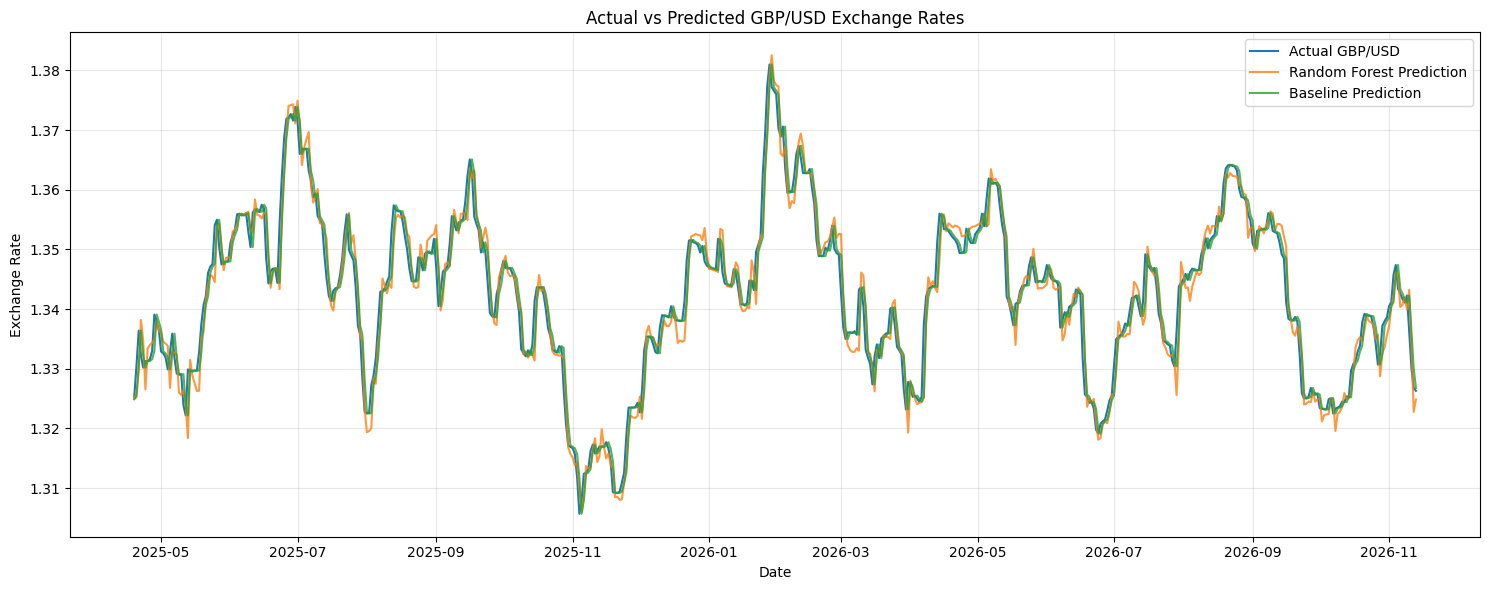

In [26]:

# Compare actual and predicted exchange rates

comparison = pd.DataFrame({
    "Date": forecast_df["date"].iloc[split_index:].values,
    "Actual": y_test.values,
    "Random Forest": rf_predictions,
    "Baseline": baseline_predictions
})

plt.figure(figsize=(15, 6))

plt.plot(
    comparison["Date"],
    comparison["Actual"],
    label="Actual GBP/USD",
    linewidth=1.5
)

plt.plot(
    comparison["Date"],
    comparison["Random Forest"],
    label="Random Forest Prediction",
    alpha=0.8
)

plt.plot(
    comparison["Date"],
    comparison["Baseline"],
    label="Baseline Prediction",
    alpha=0.8
)

plt.title("Actual vs Predicted GBP/USD Exchange Rates")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


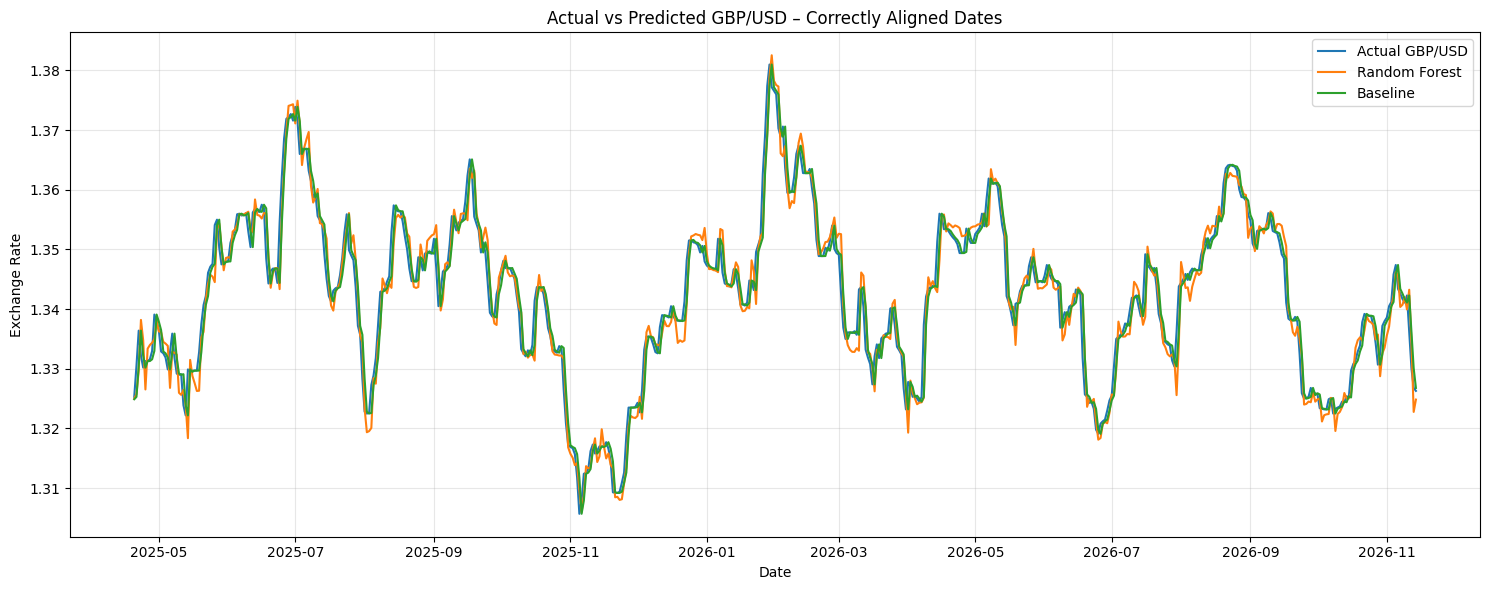

In [28]:

# Align predictions with the dates of the actual target values

target_dates = df_wide["date"].iloc[8 + split_index:]

comparison = pd.DataFrame({
    "Date": target_dates.values,
    "Actual": y_test.values,
    "Random Forest": rf_predictions,
    "Baseline": baseline_predictions
})

plt.figure(figsize=(15, 6))

plt.plot(comparison["Date"], comparison["Actual"],
         label="Actual GBP/USD")

plt.plot(comparison["Date"], comparison["Random Forest"],
         label="Random Forest")

plt.plot(comparison["Date"], comparison["Baseline"],
         label="Baseline")

plt.title("Actual vs Predicted GBP/USD – Correctly Aligned Dates")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [29]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test)

# Evaluate the model
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Results")
print("-------------------------")
print(f"MAE:  {lr_mae:.4f}")
print(f"RMSE: {lr_rmse:.4f}")
print(f"R2 Score: {lr_r2:.4f}")


Linear Regression Results
-------------------------
MAE:  0.0018
RMSE: 0.0026
R2 Score: 0.9605


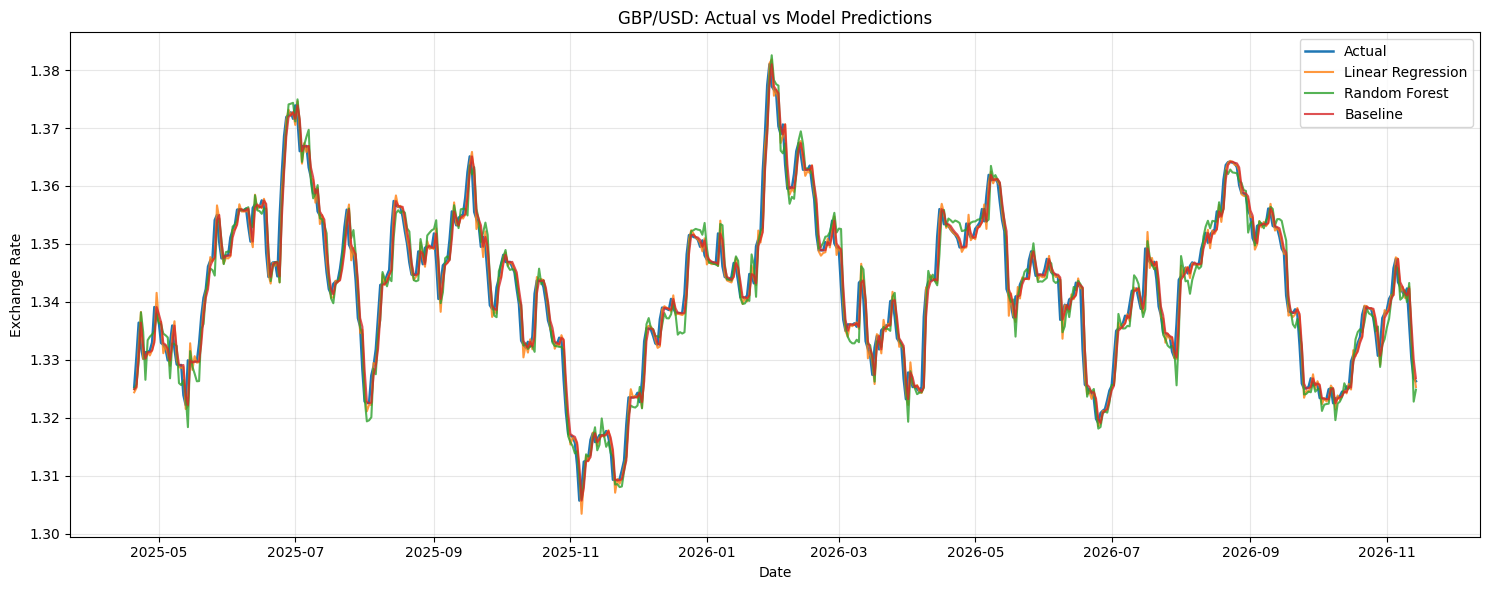

In [30]:

comparison = pd.DataFrame({
    "Date": target_dates.values,
    "Actual": y_test.values,
    "Linear Regression": lr_predictions,
    "Random Forest": rf_predictions,
    "Baseline": baseline_predictions
})

plt.figure(figsize=(15, 6))

plt.plot(comparison["Date"], comparison["Actual"],
         label="Actual", linewidth=1.8)

plt.plot(comparison["Date"], comparison["Linear Regression"],
         label="Linear Regression", alpha=0.8)

plt.plot(comparison["Date"], comparison["Random Forest"],
         label="Random Forest", alpha=0.8)

plt.plot(comparison["Date"], comparison["Baseline"],
         label="Baseline", alpha=0.8)

plt.title("GBP/USD: Actual vs Model Predictions")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [31]:

model_comparison = pd.DataFrame({
    "Model": ["Baseline", "Random Forest", "Linear Regression"],
    "MAE": [baseline_mae, rf_mae, lr_mae],
    "RMSE": [baseline_rmse, rf_rmse, lr_rmse],
    "R2 Score": [baseline_r2, rf_r2, lr_r2]
})

model_comparison = model_comparison.sort_values(
    by="MAE"
).reset_index(drop=True)

print(model_comparison.round(4).to_string(index=False))


            Model    MAE   RMSE  R2 Score
Linear Regression 0.0018 0.0026    0.9605
         Baseline 0.0035 0.0048    0.8690
    Random Forest 0.0041 0.0055    0.8293


In [32]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

predictions = {
    "Linear Regression": lr_predictions,
    "Baseline": baseline_predictions,
    "Random Forest": rf_predictions
}

results = []

for model_name, predictions_array in predictions.items():
    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions_array),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions_array)),
        "R2 Score": r2_score(y_test, predictions_array)
    })

model_comparison = pd.DataFrame(results)
model_comparison = model_comparison.sort_values("MAE")

print(model_comparison.round(4).to_string(index=False))


            Model    MAE   RMSE  R2 Score
Linear Regression 0.0018 0.0026    0.9605
         Baseline 0.0020 0.0029    0.9525
    Random Forest 0.0024 0.0033    0.9392


In [33]:

weekend_df = df_wide.copy()

weekend_df["Day"] = weekend_df["date"].dt.day_name()
weekend_df["Is_Weekend"] = weekend_df["date"].dt.dayofweek >= 5

print("Records by day of the week:")
print(weekend_df["Day"].value_counts().reindex([
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]))

print("\nWeekend records:")
print(weekend_df["Is_Weekend"].value_counts())

print("\nWeekend rate changes compared with the previous date:")

for currency in ["EUR", "USD", "INR"]:
    weekend_changes = weekend_df.loc[
        weekend_df["Is_Weekend"], currency
    ].diff()

    print(
        f"{currency}: "
        f"{(weekend_changes != 0).sum()} changes "
        f"among consecutive weekend records"
    )


Records by day of the week:
Day
Monday       410
Tuesday      411
Wednesday    411
Thursday     411
Friday       411
Saturday     411
Sunday       410
Name: count, dtype: int64

Weekend records:
Is_Weekend
False    2054
True      821
Name: count, dtype: int64

Weekend rate changes compared with the previous date:
EUR: 755 changes among consecutive weekend records
USD: 777 changes among consecutive weekend records
INR: 774 changes among consecutive weekend records


In [34]:

weekend_check = df_wide.copy()

weekend_check["Day"] = weekend_check["date"].dt.day_name()

for currency in ["EUR", "USD", "INR"]:
    weekend_check[f"{currency}_Change"] = (
        weekend_check[currency].diff()
    )

print("Weekend rate movements:")
print(
    weekend_check[weekend_check["date"].dt.dayofweek >= 5][
        ["date", "Day", "EUR", "EUR_Change",
         "USD", "USD_Change", "INR", "INR_Change"]
    ].head(15).round(5).to_string(index=False)
)


Weekend rate movements:
      date      Day    EUR  EUR_Change    USD  USD_Change     INR  INR_Change
2019-01-05 Saturday 1.1096      0.0003 1.2643      0.0006 88.3300     -0.0300
2019-01-06   Sunday 1.1099      0.0003 1.2649      0.0006 88.3300      0.0000
2019-01-12 Saturday 1.1102      0.0010 1.2778      0.0007 90.1100      0.1500
2019-01-13   Sunday 1.1100     -0.0002 1.2778      0.0000 90.1100      0.0000
2019-01-19 Saturday 1.1350      0.0008 1.2933      0.0004 91.9900      0.0500
2019-01-20   Sunday 1.1346     -0.0004 1.2933      0.0000 91.9900      0.0000
2019-01-26 Saturday 1.1539      0.0007 1.3094      0.0008 93.0900      0.0400
2019-01-27   Sunday 1.1542      0.0003 1.3098      0.0004 93.1100      0.0200
2019-02-02 Saturday 1.1419      0.0001 1.3091     -0.0001 93.2000      0.0800
2019-02-03   Sunday 1.1418     -0.0001 1.3089     -0.0002 93.2000      0.0000
2019-02-09 Saturday 1.1418      0.0007 1.2947      0.0001 92.3400     -0.0100
2019-02-10   Sunday 1.1421      0.0003 1

In [35]:

daily_returns = df_wide[["EUR", "USD", "INR"]].pct_change(fill_method=None)

volatility_comparison = pd.DataFrame({
    "252-day annualisation (%)": daily_returns.std() * np.sqrt(252) * 100,
    "365-day annualisation (%)": daily_returns.std() * np.sqrt(365) * 100
})

print(volatility_comparison.round(2))


     252-day annualisation (%)  365-day annualisation (%)
EUR                     3.3500                     4.0300
USD                     4.7400                     5.7100
INR                     4.6000                     5.5300
